# Facial Feature Classification

## 1. Dataset Exploration


In [2]:
import pandas as pd

df = pd.read_csv("../data/train_labels.csv", dtype={"image_id": str})

print("Dataset shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nMissing values:")
print(df.isnull().sum())
df.head()

Dataset shape: (63660, 2)

Columns: ['image_id', 'class']

Missing values:
image_id    0
class       0
dtype: int64


,image_id,class
0,00001,DogEye
1,00002,DogMouth
2,00003,DogFace
3,00004,DogNose
4,00005,DogNose


In [3]:
class_counts = df["class"].value_counts()

print("Number of classes:", df["class"].nunique())
print("\nImages per class:")
print(class_counts)

Number of classes: 8

Images per class:
class
CatEye      13884
DogEye      11580
CatNose      6942
CatFace      6942
CatMouth     6942
DogMouth     5790
DogFace      5790
DogNose      5790
Name: count, dtype: int64


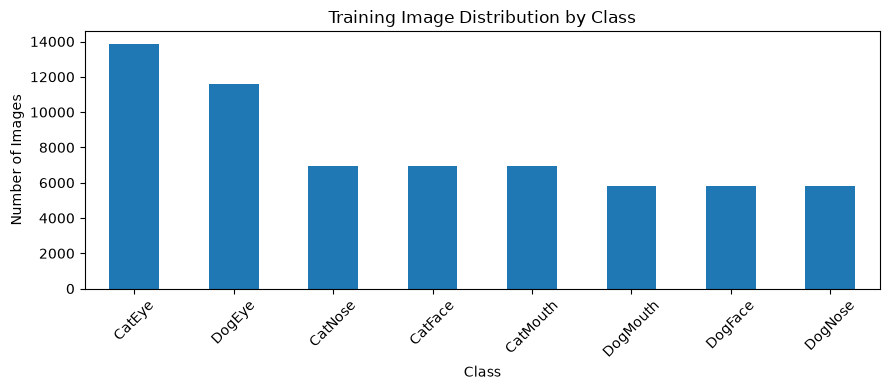

In [4]:
import matplotlib.pyplot as plt

class_counts.plot(kind="bar", figsize=(9, 4))
plt.title("Training Image Distribution by Class")
plt.xlabel("Class")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

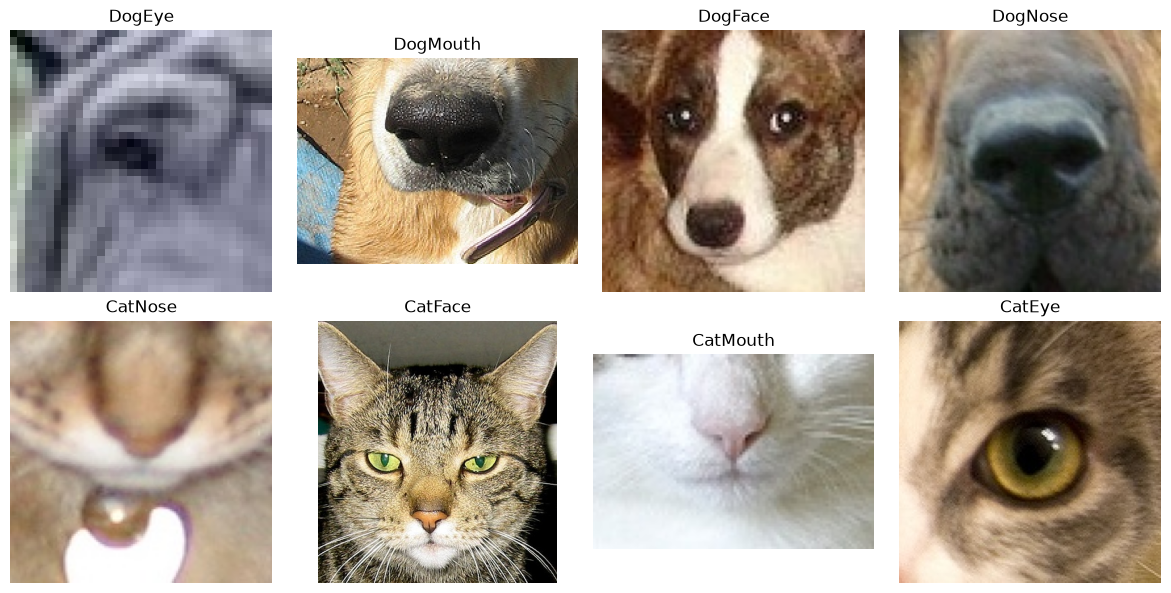

In [5]:
from PIL import Image
import matplotlib.pyplot as plt
from pathlib import Path

train_dir = Path("../data/train/train")

fig, axes = plt.subplots(2, 4, figsize=(12, 6))

for ax, (_, row) in zip(axes.flat, df.drop_duplicates(subset="class").iterrows()):
    image_path = train_dir / f"{row['image_id']}.jpg"
    image = Image.open(image_path)
    ax.imshow(image)
    ax.set_title(row["class"])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [6]:
duplicate_ids = df["image_id"].duplicated().sum()

print("Duplicate image IDs:", duplicate_ids)

Duplicate image IDs: 0


In [7]:
image_sizes = []

for image_id in df["image_id"].head(100):
    image_path = train_dir / f"{image_id}.jpg"

    with Image.open(image_path) as image:
        image_sizes.append(image.size)

print("Different image dimensions:", set(image_sizes))

Different image dimensions: {(256, 288), (56, 56), (70, 70), (52, 52), (116, 116), (38, 38), (20, 20), (94, 70), (112, 112), (176, 176), (176, 124), (66, 66), (54, 40), (130, 130), (140, 140), (34, 34), (48, 48), (64, 47), (64, 44), (158, 158), (171, 210), (30, 30), (62, 62), (104, 77), (166, 116), (316, 222), (108, 108), (26, 26), (86, 86), (112, 163), (94, 66), (191, 191), (68, 50), (40, 40), (34, 24), (178, 178), (114, 114), (68, 68), (149, 148), (132, 132), (207, 232), (36, 36), (54, 54), (100, 100), (110, 110), (78, 54), (32, 32), (96, 96), (128, 128), (64, 64), (122, 90), (266, 266), (158, 117), (387, 388), (188, 182), (60, 60), (82, 82), (343, 376), (78, 78), (182, 135), (478, 585), (24, 24), (97, 97), (106, 106), (98, 68), (142, 105), (28, 28), (74, 74), (155, 154), (157, 157), (250, 358), (148, 148), (50, 37), (90, 64), (214, 157), (42, 42)}


In [8]:
missing_images = [
    image_id for image_id in df["image_id"]
    if not (train_dir / f"{image_id}.jpg").exists()
]

print("Missing training images:", len(missing_images))

Missing training images: 0


In [9]:
corrupted_images = []

for image_id in df["image_id"]:
    image_path = train_dir / f"{image_id}.jpg"

    try:
        with Image.open(image_path) as image:
            image.verify()
    except Exception:
        corrupted_images.append(image_id)

print("Corrupted images:", len(corrupted_images))

Corrupted images: 0


In [10]:
import hashlib

image_hashes = {}
duplicate_images = []

for image_id in df["image_id"]:
    image_path = train_dir / f"{image_id}.jpg"

    with open(image_path, "rb") as file:
        image_hash = hashlib.sha256(file.read()).hexdigest()

    if image_hash in image_hashes:
        duplicate_images.append((image_hashes[image_hash], image_id))
    else:
        image_hashes[image_hash] = image_id

print("Exact duplicate image files:", len(duplicate_images))
print("Examples:", duplicate_images[:5])

Exact duplicate image files: 15
Examples: [('00356', '06903'), ('07219', '12150'), ('16730', '21960'), ('25436', '40256'), ('03365', '42280')]


In [11]:
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["class"]
)

train_ids = set(train_df["image_id"])
val_ids = set(val_df["image_id"])

leakage_pairs = []

for id1, id2 in duplicate_images:
    if (id1 in train_ids and id2 in val_ids) or (id2 in train_ids and id1 in val_ids):
        leakage_pairs.append((id1, id2))

print("Duplicate pairs crossing train/validation:", len(leakage_pairs))
print("Pairs:", leakage_pairs)

Duplicate pairs crossing train/validation: 3
Pairs: [('00356', '06903'), ('03926', '56008'), ('13090', '63140')]


## 2. Data Preprocessing

### 2.1 Training and Validation Split

In [12]:
from sklearn.model_selection import train_test_split

train_df, val_df = train_test_split(
    df,
    test_size=0.2,
    random_state=42,
    stratify=df["class"]
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))

Training images: 50928
Validation images: 12732


In [14]:
import tensorflow as tf

class_names = sorted(df["class"].unique())
class_to_index = {name: i for i, name in enumerate(class_names)}

train_paths = [str(train_dir / f"{image_id}.jpg") for image_id in train_df["image_id"]]
val_paths = [str(train_dir / f"{image_id}.jpg") for image_id in val_df["image_id"]]

train_labels = train_df["class"].map(class_to_index).to_numpy()
val_labels = val_df["class"].map(class_to_index).to_numpy()

print(class_to_index)
print("Training paths:", len(train_paths))
print("Validation paths:", len(val_paths))

{'CatEye': 0, 'CatFace': 1, 'CatMouth': 2, 'CatNose': 3, 'DogEye': 4, 'DogFace': 5, 'DogMouth': 6, 'DogNose': 7}
Training paths: 50928
Validation paths: 12732


In [17]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize_with_pad(image, 128, 128)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label

train_ds = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
val_ds = tf.data.Dataset.from_tensor_slices((val_paths, val_labels))

train_ds = train_ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
val_ds = val_ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)

train_ds = train_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [18]:
for images, labels in train_ds.take(1):
    print("Images shape:", images.shape)
    print("Labels shape:", labels.shape)
    print("Pixel range:", float(tf.reduce_min(images)), float(tf.reduce_max(images)))

Images shape: (32, 128, 128, 3)
Labels shape: (32,)
Pixel range: 0.0 1.0


## 3. CNN Model Development
### 3.1 Baseline CNN

In [14]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation="relu"),
    layers.Dense(8, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,305,672 (12.61 MB)

 Trainable params: 3,305,672 (12.61 MB)

 Non-trainable params: 0 (0.00 B)

### 3.2 Compile and Train Baseline CNN

In [15]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [16]:
train_ds = train_ds.shuffle(5000, seed=42)

In [17]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

Epoch 1/5


/Users/chaimaoueslati/Desktop/Data ENG and AI/data_ai_foundations/facial_feature_classifier/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1592/1592 ━━━━━━━━━━━━━━━━━━━━ 267s 162ms/step - accuracy: 0.9266 - loss: 0.2282 - val_accuracy: 0.9665 - val_loss: 0.1060
Epoch 2/5
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 249s 151ms/step - accuracy: 0.9729 - loss: 0.0825 - val_accuracy: 0.9779 - val_loss: 0.0709
Epoch 3/5
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 238s 146ms/step - accuracy: 0.9843 - loss: 0.0462 - val_accuracy: 0.9732 - val_loss: 0.0849
Epoch 4/5
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 234s 143ms/step - accuracy: 0.9884 - loss: 0.0339 - val_accuracy: 0.9728 - val_loss: 0.0998
Epoch 5/5
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 230s 141ms/step - accuracy: 0.9915 - loss: 0.0232 - val_accuracy: 0.9732 - val_loss: 0.1216


### Experiment 1: Baseline 

**Configuration**
- Input image size: 128 × 128 × 3
- Batch size: 32
- 3 convolutional layers (32, 64, 128 filters), max pooling, flatten, dense layer (128 neurons), softmax output (8 classes)
- Optimiser: Adam
- Learning rate: 0.001
- Loss function: Sparse categorical crossentropy
- Epochs: 5
- Training images: 50,928
- Validation images: 12,732

**Results**
| Epoch | Train accuracy | Validation accuracy | Train loss | Validation loss |
|---|---|---|---|---|
| 1 | 92.66% | 96.65% | 0.2282 | 0.1060 |
| 2 | 97.29% | 97.79% | 0.0825 | 0.0709 |
| 3 | 98.43% | 97.32% | 0.0462 | 0.0849 |
| 4 | 98.84% | 97.28% | 0.0339 | 0.0998 |
| 5 | 99.15% | 97.32% | 0.0232 | 0.1216 |

Epoch 2 had the highest validation accuracy and lowest validation loss in this run. Later epochs continued to improve training performance while validation loss increased.



In [18]:
import numpy as np

val_probabilities = model.predict(val_ds)
val_predictions = np.argmax(val_probabilities, axis=1)

398/398 ━━━━━━━━━━━━━━━━━━━━ 17s 43ms/step


In [19]:
from sklearn.metrics import classification_report

print(classification_report(
    val_labels,
    val_predictions,
    target_names=class_names
))

              precision    recall  f1-score   support

      CatEye       0.95      0.99      0.97      2777
     CatFace       0.97      0.99      0.98      1388
    CatMouth       0.99      1.00      0.99      1388
     CatNose       0.98      0.93      0.96      1389
      DogEye       0.97      0.95      0.96      2316
     DogFace       0.99      0.97      0.98      1158
    DogMouth       1.00      1.00      1.00      1158
     DogNose       0.98      0.96      0.97      1158

    accuracy                           0.97     12732
   macro avg       0.98      0.97      0.98     12732
weighted avg       0.97      0.97      0.97     12732



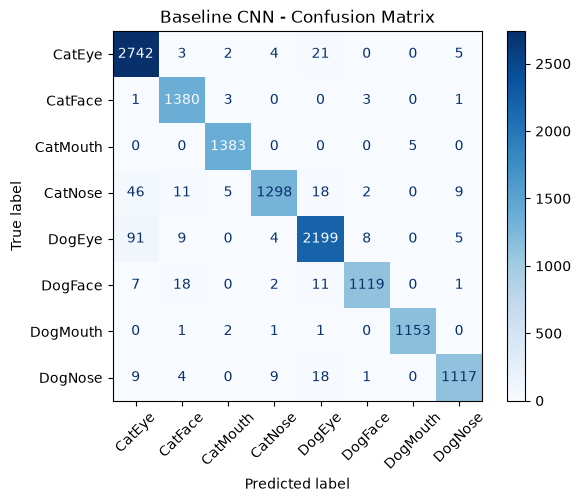

In [20]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    val_labels,
    val_predictions,
    display_labels=class_names,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Baseline CNN - Confusion Matrix")
plt.show()

In [21]:
sample_submission = pd.read_csv(
    "../data/sample_submission.csv",
    dtype={"image_id": str}
)

print(sample_submission.shape)
print(sample_submission.head())

(29443, 2)
  image_id     class
0        1    DogEye
1        2   CatNose
2        3   CatNose
3        4   DogFace
4        5  DogMouth


In [25]:
test_dir = Path("../data/test/test")
test_paths = []

for image_id in sample_submission["image_id"]:
    filename = f"{int(image_id):05d}.jpg"
    full_path = test_dir / filename
    test_paths.append(str(full_path))

print(test_paths[:5])

['../data/test/test/00001.jpg', '../data/test/test/00002.jpg', '../data/test/test/00003.jpg', '../data/test/test/00004.jpg', '../data/test/test/00005.jpg']


In [26]:
def load_test_image(path):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize_with_pad(image, 128, 128)
    image = tf.cast(image, tf.float32) / 255.0
    return image

test_ds = tf.data.Dataset.from_tensor_slices(test_paths)
test_ds = test_ds.map(load_test_image, num_parallel_calls=tf.data.AUTOTUNE)
test_ds = test_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [27]:
test_probabilities = model.predict(test_ds)
test_predictions = np.argmax(test_probabilities, axis=1)

print(test_probabilities.shape)
print(test_predictions.shape)

921/921 ━━━━━━━━━━━━━━━━━━━━ 38s 41ms/step
(29443, 8)
(29443,)


In [29]:
test_class_names = []

for i in test_predictions:
    test_class_names.append(class_names[i])

In [31]:
submission = sample_submission.copy()

submission["class"] = test_class_names

print(submission.shape)
print(submission.head())

submission.to_csv("../data/submission_baseline.csv", index=False)

(29443, 2)
  image_id     class
0        1    DogEye
1        2  DogMouth
2        3   DogNose
3        4   DogFace
4        5  CatMouth


In [32]:
print(class_names)
print(submission["class"].unique())

['CatEye', 'CatFace', 'CatMouth', 'CatNose', 'DogEye', 'DogFace', 'DogMouth', 'DogNose']
<StringArray>
[  'DogEye', 'DogMouth',  'DogNose',  'DogFace', 'CatMouth',  'CatFace',
   'CatEye',  'CatNose']
Length: 8, dtype: str


In [33]:
print(sample_submission.head(10))
print(sample_submission["class"].unique())

  image_id     class
0        1    DogEye
1        2   CatNose
2        3   CatNose
3        4   DogFace
4        5  DogMouth
5        6   CatNose
6        7  CatMouth
7        8    DogEye
8        9  DogMouth
9       10   CatFace
<StringArray>
[  'DogEye',  'CatNose',  'DogFace', 'DogMouth', 'CatMouth',  'CatFace',
  'DogNose',   'CatEye']
Length: 8, dtype: str


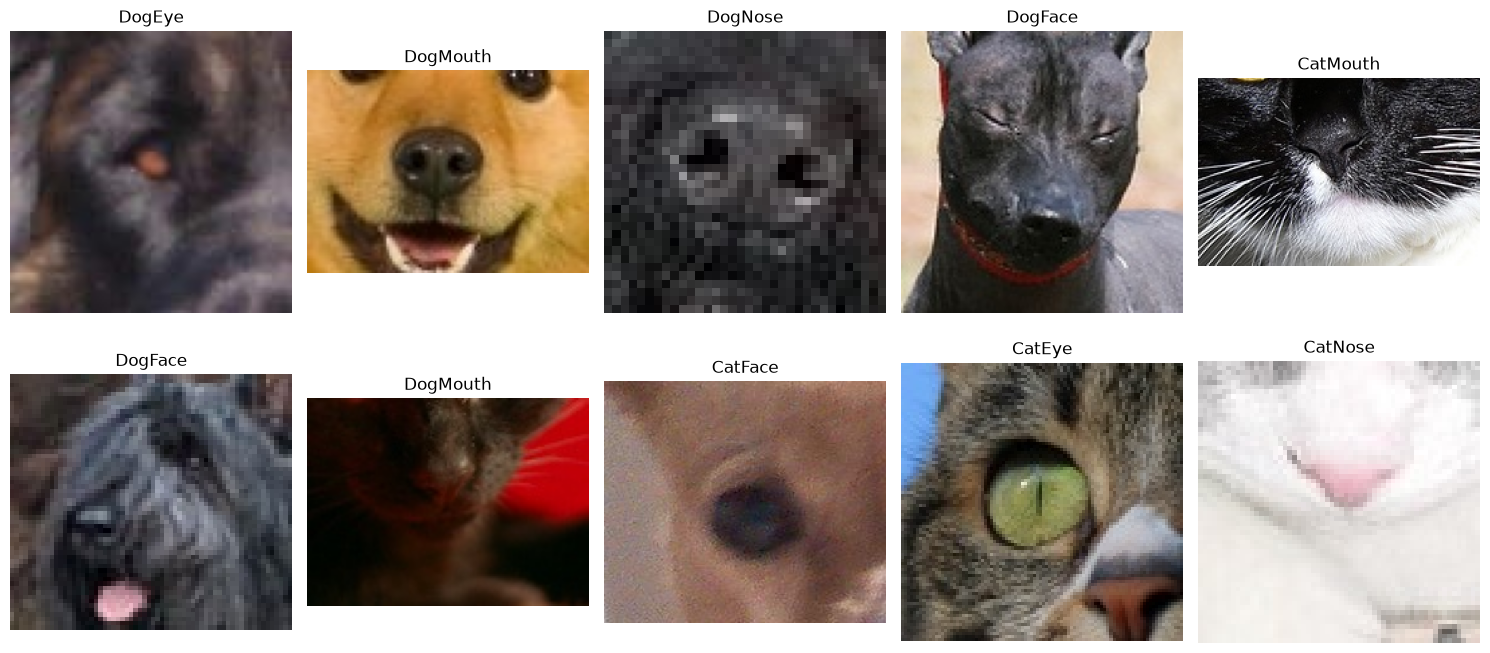

In [35]:
fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for i, ax in enumerate(axes.flat):
    image = plt.imread(test_paths[i])
    ax.imshow(image)
    ax.set_title(test_class_names[i])
    ax.axis("off")

plt.tight_layout()
plt.show()

## Experiment 2: Transfer Learning with MobileNetV2

**Objective:** Investigate whether a pretrained MobileNetV2 model improves image classification compared with the baseline CNN.

- Use MobileNetV2 with pretrained ImageNet weights.
- Freeze the pretrained layers and train a new classifier for our eight classes.

**Initial settings:**
- Image size: 128 × 128
- Batch size: 32
- Optimizer: Adam
- Learning rate: 0.001
- Maximum epochs: 5
- Dropout: 0.3
- Early stopping patience: 2

In [31]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

def load_mobilenet_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize_with_pad(image, 128, 128)
    image = preprocess_input(image)
    return image, label

train_ds2 = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
train_ds2 = train_ds2.shuffle(5000, seed=42)
train_ds2 = train_ds2.map(load_mobilenet_image, num_parallel_calls=tf.data.AUTOTUNE)
train_ds2 = train_ds2.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_ds2 = tf.data.Dataset.from_tensor_slices((val_paths, val_labels))
val_ds2 = val_ds2.map(load_mobilenet_image, num_parallel_calls=tf.data.AUTOTUNE)
val_ds2 = val_ds2.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [37]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(128, 128, 3)
)

base_model.trainable = False

model2 = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(8, activation="softmax")
])

model2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model2.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 8)              │         1,032 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,984 (9.24 MB)

 Trainable params: 165,000 (644.53 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [38]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history2 = model2.fit(
    train_ds2,
    validation_data=val_ds2,
    epochs=5,
    callbacks=[early_stopping]
)

val_loss2, val_accuracy2 = model2.evaluate(val_ds2)

print("Experiment 2 validation accuracy:", val_accuracy2)

Epoch 1/5


/Users/chaimaoueslati/Desktop/Data ENG and AI/data_ai_foundations/facial_feature_classifier/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1592/1592 ━━━━━━━━━━━━━━━━━━━━ 182s 113ms/step - accuracy: 0.9214 - loss: 0.2243 - val_accuracy: 0.9583 - val_loss: 0.1189
Epoch 2/5
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 172s 108ms/step - accuracy: 0.9541 - loss: 0.1310 - val_accuracy: 0.9641 - val_loss: 0.1026
Epoch 3/5
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 179s 112ms/step - accuracy: 0.9612 - loss: 0.1077 - val_accuracy: 0.9625 - val_loss: 0.1107
Epoch 4/5
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 186s 117ms/step - accuracy: 0.9675 - loss: 0.0911 - val_accuracy: 0.9642 - val_loss: 0.1090
398/398 ━━━━━━━━━━━━━━━━━━━━ 32s 81ms/step - accuracy: 0.9641 - loss: 0.1026
Experiment 2 validation accuracy: 0.9641062021255493


In [42]:
model2.save("../data/mobilenet_v2.keras")

In [39]:
def load_mobilenet_test_image(path):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize_with_pad(image, 128, 128)
    image = preprocess_input(image)
    return image

test_ds2 = tf.data.Dataset.from_tensor_slices(test_paths)
test_ds2 = test_ds2.map(load_mobilenet_test_image, num_parallel_calls=tf.data.AUTOTUNE)
test_ds2 = test_ds2.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_probabilities2 = model2.predict(test_ds2)
test_predictions2 = np.argmax(test_probabilities2, axis=1)

test_class_names2 = []
for i in test_predictions2:
    test_class_names2.append(class_names[i])

submission2 = sample_submission.copy()
submission2["class"] = test_class_names2
submission2.to_csv("../data/submission_mobilenet.csv", index=False)

print(submission2.shape)
print(submission2.head())

921/921 ━━━━━━━━━━━━━━━━━━━━ 80s 86ms/step
(29443, 2)
  image_id     class
0        1    DogEye
1        2  DogMouth
2        3   DogNose
3        4   DogFace
4        5  CatMouth


### Experiment 2 Results

- Training completed: 4 epochs 
- Best epoch by validation loss: 2
- Validation accuracy: 96.41%
- Validation loss: 0.1026
- Kaggle accuracy: 86.91%


### Experiment 2: Detailed Validation Evaluation

398/398 ━━━━━━━━━━━━━━━━━━━━ 33s 82ms/step
              precision    recall  f1-score   support

      CatEye       0.96      0.97      0.97      2777
     CatFace       1.00      0.99      0.99      1388
    CatMouth       0.97      0.99      0.98      1388
     CatNose       0.94      0.96      0.95      1389
      DogEye       0.95      0.92      0.94      2316
     DogFace       0.99      0.98      0.98      1158
    DogMouth       0.99      0.98      0.98      1158
     DogNose       0.91      0.94      0.93      1158

    accuracy                           0.96     12732
   macro avg       0.97      0.97      0.97     12732
weighted avg       0.96      0.96      0.96     12732



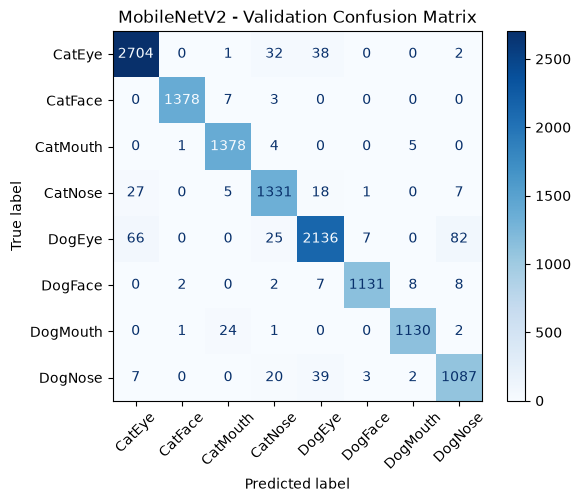

In [41]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

val_probabilities2 = model2.predict(val_ds2)
val_predictions2 = np.argmax(val_probabilities2, axis=1)

print(classification_report(
    val_labels,
    val_predictions2,
    target_names=class_names
))

ConfusionMatrixDisplay.from_predictions(
    val_labels,
    val_predictions2,
    display_labels=class_names,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("MobileNetV2 - Validation Confusion Matrix")
plt.show()

## Experiment 3: Fine-tuning MobileNetV2

This experiment continues training the MobileNetV2 model from Experiment 2.
The last 30 pretrained layers are allowed to learn from the facial-feature
dataset, while earlier layers remain frozen.


In [43]:
# Allow MobileNetV2's layers to be trainable
base_model.trainable = True

# Keep all except the last 30 layers frozen
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Keep BatchNormalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Recompile 
model2.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# Stop training if validation loss stops improving
early_stopping3 = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)


history3 = model2.fit(
    train_ds2,
    validation_data=val_ds2,
    epochs=5,
    callbacks=[early_stopping3]
)

# Evaluate
val_loss3, val_accuracy3 = model2.evaluate(val_ds2)

print("Experiment 3 validation accuracy:", val_accuracy3)
print("Experiment 3 validation loss:", val_loss3)

Epoch 1/5


/Users/chaimaoueslati/Desktop/Data ENG and AI/data_ai_foundations/facial_feature_classifier/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1592/1592 ━━━━━━━━━━━━━━━━━━━━ 181s 112ms/step - accuracy: 0.9724 - loss: 0.0779 - val_accuracy: 0.9712 - val_loss: 0.0811
Epoch 2/5
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 168s 105ms/step - accuracy: 0.9831 - loss: 0.0487 - val_accuracy: 0.9760 - val_loss: 0.0699
Epoch 3/5
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 171s 107ms/step - accuracy: 0.9877 - loss: 0.0339 - val_accuracy: 0.9805 - val_loss: 0.0568
Epoch 4/5
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 351s 221ms/step - accuracy: 0.9915 - loss: 0.0240 - val_accuracy: 0.9822 - val_loss: 0.0575
Epoch 5/5
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 175s 110ms/step - accuracy: 0.9937 - loss: 0.0186 - val_accuracy: 0.9819 - val_loss: 0.0628
398/398 ━━━━━━━━━━━━━━━━━━━━ 32s 80ms/step - accuracy: 0.9805 - loss: 0.0568
Experiment 3 validation accuracy: 0.9805215001106262
Experiment 3 validation loss: 0.056751079857349396


In [44]:
model2.save("../data/mobilenet_v2_finetuned.keras")

398/398 ━━━━━━━━━━━━━━━━━━━━ 33s 82ms/step
              precision    recall  f1-score   support

      CatEye       0.99      0.97      0.98      2777
     CatFace       1.00      1.00      1.00      1388
    CatMouth       0.99      1.00      0.99      1388
     CatNose       0.95      0.97      0.96      1389
      DogEye       0.97      0.97      0.97      2316
     DogFace       0.99      0.99      0.99      1158
    DogMouth       1.00      0.99      0.99      1158
     DogNose       0.97      0.97      0.97      1158

    accuracy                           0.98     12732
   macro avg       0.98      0.98      0.98     12732
weighted avg       0.98      0.98      0.98     12732



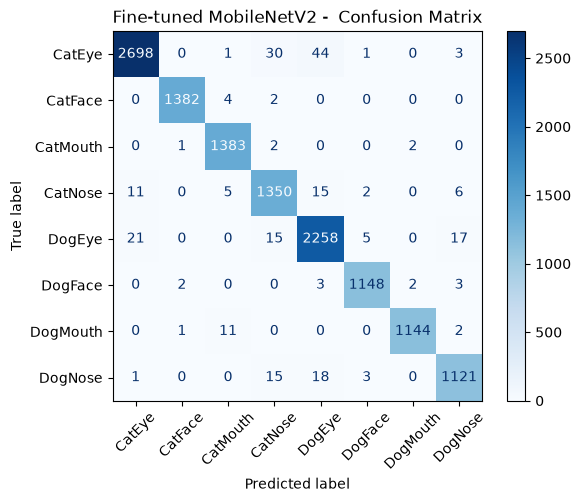

In [46]:
val_probabilities3 = model2.predict(val_ds2)
val_predictions3 = np.argmax(val_probabilities3, axis=1)

print(classification_report(
    val_labels,
    val_predictions3,
    target_names=class_names
))

ConfusionMatrixDisplay.from_predictions(
    val_labels,
    val_predictions3,
    display_labels=class_names,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Fine-tuned MobileNetV2 -  Confusion Matrix")
plt.show()

### Experiment 3: Kaggle Test Predictions

In [47]:
# Predict using the fine-tuned model
test_probabilities3 = model2.predict(test_ds2)

# Find the class with the highest probability
test_predictions3 = np.argmax(test_probabilities3, axis=1)

# Convert class indices into class names
test_class_names3 = []

for i in test_predictions3:
    test_class_names3.append(class_names[i])

# Create the submission
submission3 = sample_submission.copy()
submission3["class"] = test_class_names3


submission3.to_csv("../data/submission_mobilenet_finetuned.csv", index=False)

print(submission3.shape)
print(submission3.head())

921/921 ━━━━━━━━━━━━━━━━━━━━ 76s 82ms/step
(29443, 2)
  image_id     class
0        1    DogEye
1        2  DogMouth
2        3   DogNose
3        4   DogFace
4        5  CatMouth


### Experiment 3 Results

- Training completed: 5 epochs
- Best epoch by validation loss: 3
- Validation accuracy: 98.05%
- Validation loss: 0.0568
- Kaggle public accuracy: 90.33%

#### Experiment 4: Fine-tuning with data augmentation

In [19]:
# Experiment 4: Fine-tuning with data augmentation

augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.1),
], name="data_augmentation")

# Start from the same saved model used before fine-tuning
model4 = tf.keras.models.load_model("../data/mobilenet_v2.keras")

# The MobileNetV2 base is the first layer of our Sequential model
base_model4 = model4.layers[0]

# Unfreeze only the last 30 layers
base_model4.trainable = True

for layer in base_model4.layers[:-30]:
    layer.trainable = False

# Keep BatchNormalization layers frozen
for layer in base_model4.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Apply augmentation before the model
inputs = tf.keras.Input(shape=(128, 128, 3))
x = augmentation(inputs)
outputs = model4(x)

model4_augmented = tf.keras.Model(inputs, outputs)

model4_augmented.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

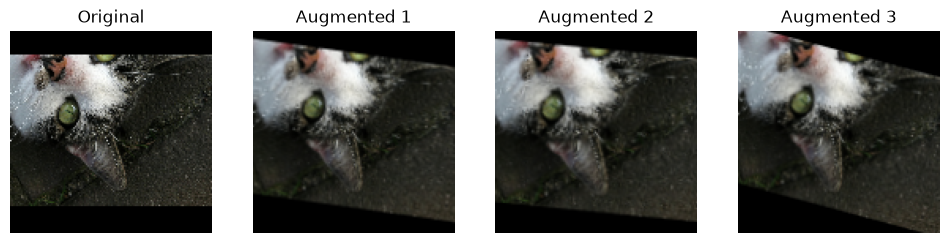

In [25]:
sample_path = train_paths[0]

image, label = load_image(
    tf.constant(sample_path),
    tf.constant(train_labels[0])
)

plt.figure(figsize=(12, 3))

plt.subplot(1, 4, 1)
plt.imshow(image.numpy())
plt.title("Original")
plt.axis("off")

for i in range(3):
    augmented_image = augmentation(
        tf.expand_dims(image, axis=0),
        training=True
    )[0]

    plt.subplot(1, 4, i + 2)
    plt.imshow(tf.clip_by_value(augmented_image, 0, 1).numpy())
    plt.title(f"Augmented {i + 1}")
    plt.axis("off")

plt.show()

In [49]:
early_stopping4 = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history4 = model4_augmented.fit(
    train_ds2,
    validation_data=val_ds2,
    epochs=5,
    callbacks=[early_stopping4]
)

val_loss4, val_accuracy4 = model4_augmented.evaluate(val_ds2)

print("Experiment 4 validation accuracy:", val_accuracy4)
print("Experiment 4 validation loss:", val_loss4)

Epoch 1/5


/Users/chaimaoueslati/Desktop/Data ENG and AI/data_ai_foundations/facial_feature_classifier/.venv/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


1592/1592 ━━━━━━━━━━━━━━━━━━━━ 195s 121ms/step - accuracy: 0.9600 - loss: 0.1169 - val_accuracy: 0.9738 - val_loss: 0.0724
Epoch 2/5
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 191s 120ms/step - accuracy: 0.9712 - loss: 0.0841 - val_accuracy: 0.9786 - val_loss: 0.0639
Epoch 3/5
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 198s 124ms/step - accuracy: 0.9774 - loss: 0.0660 - val_accuracy: 0.9797 - val_loss: 0.0589
Epoch 4/5
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 203s 128ms/step - accuracy: 0.9804 - loss: 0.0565 - val_accuracy: 0.9808 - val_loss: 0.0557
Epoch 5/5
1592/1592 ━━━━━━━━━━━━━━━━━━━━ 198s 124ms/step - accuracy: 0.9829 - loss: 0.0484 - val_accuracy: 0.9828 - val_loss: 0.0518
398/398 ━━━━━━━━━━━━━━━━━━━━ 35s 87ms/step - accuracy: 0.9828 - loss: 0.0518
Experiment 4 validation accuracy: 0.982799232006073
Experiment 4 validation loss: 0.05175047367811203


In [51]:
model4_augmented.save("../data/mobilenet_v2_augmented.keras")

398/398 ━━━━━━━━━━━━━━━━━━━━ 29s 73ms/step
              precision    recall  f1-score   support

      CatEye       0.98      0.99      0.98      2777
     CatFace       0.99      1.00      1.00      1388
    CatMouth       0.99      1.00      0.99      1388
     CatNose       0.97      0.97      0.97      1389
      DogEye       0.99      0.96      0.97      2316
     DogFace       0.97      1.00      0.99      1158
    DogMouth       1.00      0.99      0.99      1158
     DogNose       0.96      0.98      0.97      1158

    accuracy                           0.98     12732
   macro avg       0.98      0.99      0.98     12732
weighted avg       0.98      0.98      0.98     12732



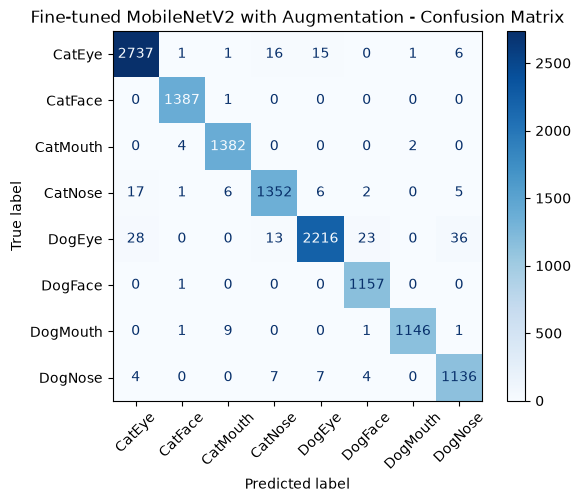

In [52]:
val_probabilities4 = model4_augmented.predict(val_ds2)
val_predictions4 = np.argmax(val_probabilities4, axis=1)

print(classification_report(
    val_labels,
    val_predictions4,
    target_names=class_names
))

ConfusionMatrixDisplay.from_predictions(
    val_labels,
    val_predictions4,
    display_labels=class_names,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("Fine-tuned MobileNetV2 with Augmentation - Confusion Matrix")
plt.show()

In [53]:
test_probabilities4 = model4_augmented.predict(test_ds2)
test_predictions4 = np.argmax(test_probabilities4, axis=1)

921/921 ━━━━━━━━━━━━━━━━━━━━ 70s 75ms/step


In [54]:
test_class_names4 = [class_names[i] for i in test_predictions4]

submission4 = sample_submission.copy()
submission4["class"] = test_class_names4

submission4.to_csv("../data/submission4.csv", index=False)

print(submission4.head())
print(submission4.shape)

  image_id     class
0        1    DogEye
1        2  DogMouth
2        3   DogNose
3        4   DogFace
4        5  CatMouth
(29443, 2)


### Experiment 4 Results

- Training completed: 5 epochs
- Best epoch by validation loss: 5
- Validation accuracy: 98.28%
- Validation loss: 0.0518
- Kaggle public accuracy: 89.03%

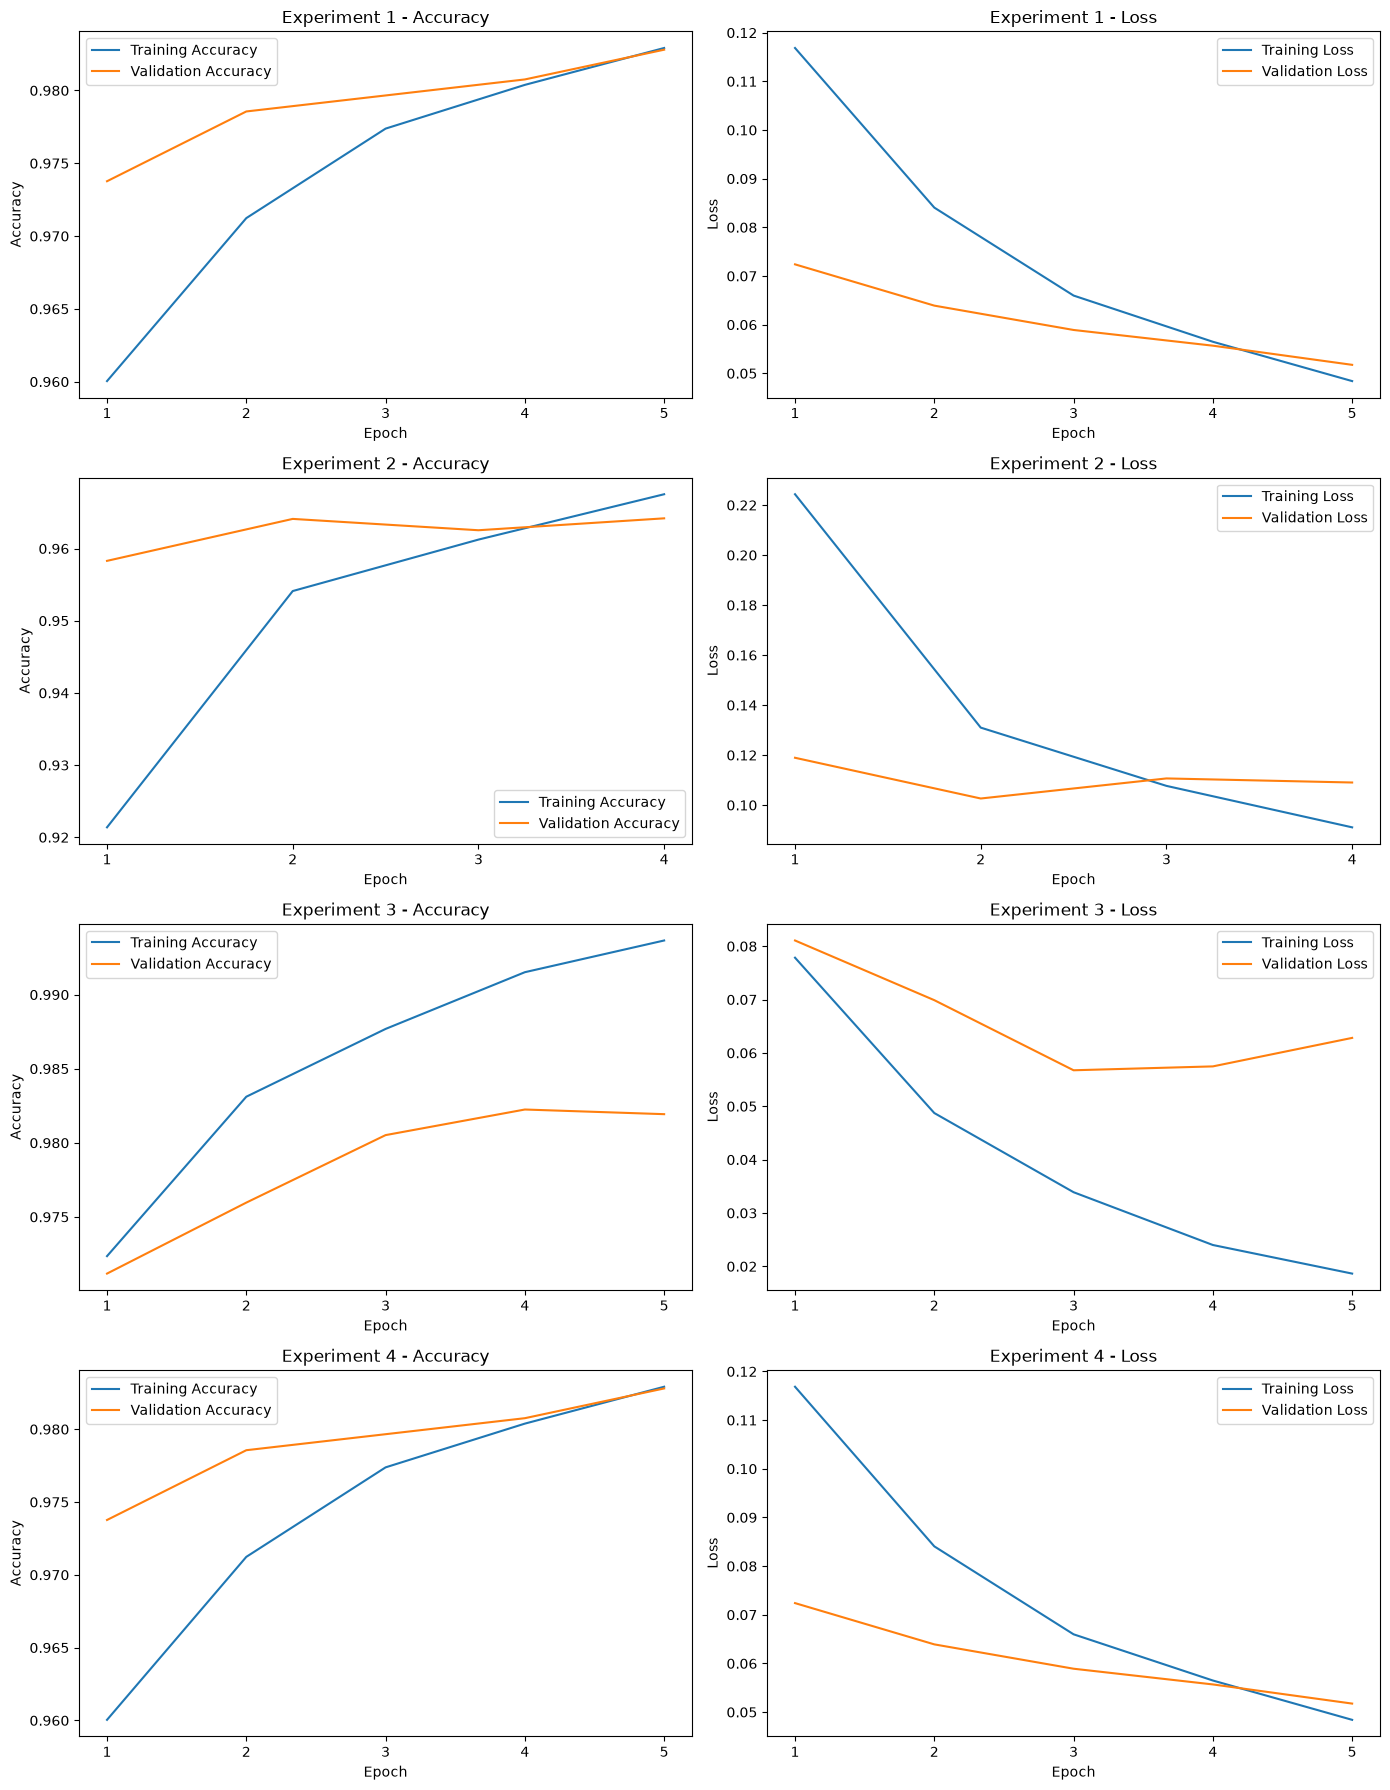

In [57]:
histories = [history, history2, history3, history4]

fig, axes = plt.subplots(4, 2, figsize=(14, 18))

for i, h in enumerate(histories):

    epochs = range(1, len(h.history["accuracy"]) + 1)

    # Left: Accuracy
    axes[i, 0].plot(epochs, h.history["accuracy"], label="Training Accuracy")
    axes[i, 0].plot(epochs, h.history["val_accuracy"], label="Validation Accuracy")
    axes[i, 0].set_title(f"Experiment {i+1} - Accuracy")
    axes[i, 0].set_xlabel("Epoch")
    axes[i, 0].set_ylabel("Accuracy")
    axes[i, 0].set_xticks(list(epochs))
    axes[i, 0].legend()

    # Right: Loss
    axes[i, 1].plot(epochs, h.history["loss"], label="Training Loss")
    axes[i, 1].plot(epochs, h.history["val_loss"], label="Validation Loss")
    axes[i, 1].set_title(f"Experiment {i+1} - Loss")
    axes[i, 1].set_xlabel("Epoch")
    axes[i, 1].set_ylabel("Loss")
    axes[i, 1].set_xticks(list(epochs))
    axes[i, 1].legend()

plt.tight_layout()
plt.show()

## 6. Final Experiment Comparison


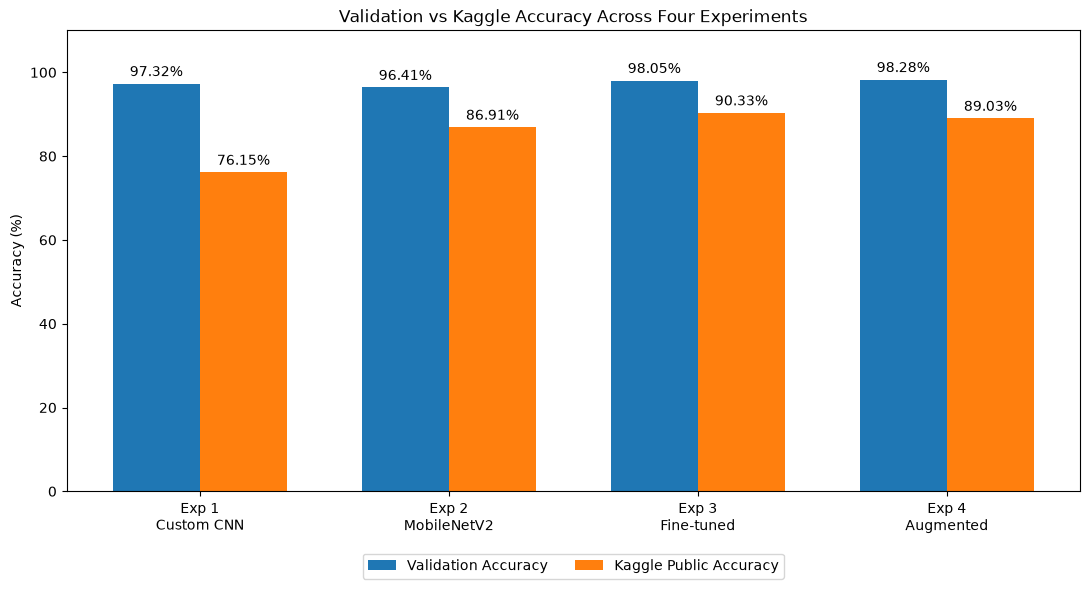

In [28]:
import matplotlib.pyplot as plt
import numpy as np

experiments = [
    "Exp 1\nCustom CNN",
    "Exp 2\nMobileNetV2",
    "Exp 3\nFine-tuned",
    "Exp 4\nAugmented"
]

validation_accuracy = [97.32, 96.41, 98.05, 98.28]
kaggle_accuracy = [76.15, 86.91, 90.33, 89.03]

x = np.arange(len(experiments))
width = 0.35

plt.figure(figsize=(11, 6))

validation_bars = plt.bar(
    x - width / 2,
    validation_accuracy,
    width,
    label="Validation Accuracy"
)

kaggle_bars = plt.bar(
    x + width / 2,
    kaggle_accuracy,
    width,
    label="Kaggle Public Accuracy"
)

plt.bar_label(validation_bars, fmt="%.2f%%", padding=3)
plt.bar_label(kaggle_bars, fmt="%.2f%%", padding=3)

plt.xticks(x, experiments)
plt.ylabel("Accuracy (%)")
plt.title("Validation vs Kaggle Accuracy Across Four Experiments")
plt.ylim(0, 110)
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)

plt.tight_layout()
plt.show()

## 7. Misclassified Validation Images

In [32]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf


best_model = tf.keras.models.load_model(
    "../data/mobilenet_v2_finetuned.keras"
)


validation_images = tf.data.Dataset.from_tensor_slices(
    (val_paths, val_labels)
)

validation_images = validation_images.map(
    load_mobilenet_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

validation_images = validation_images.batch(32)


probabilities = best_model.predict(validation_images)
predictions = np.argmax(probabilities, axis=1)


wrong_indices = np.where(predictions != val_labels)[0]

print("Misclassified validation images:", len(wrong_indices))

398/398 ━━━━━━━━━━━━━━━━━━━━ 35s 87ms/step
Misclassified validation images: 248


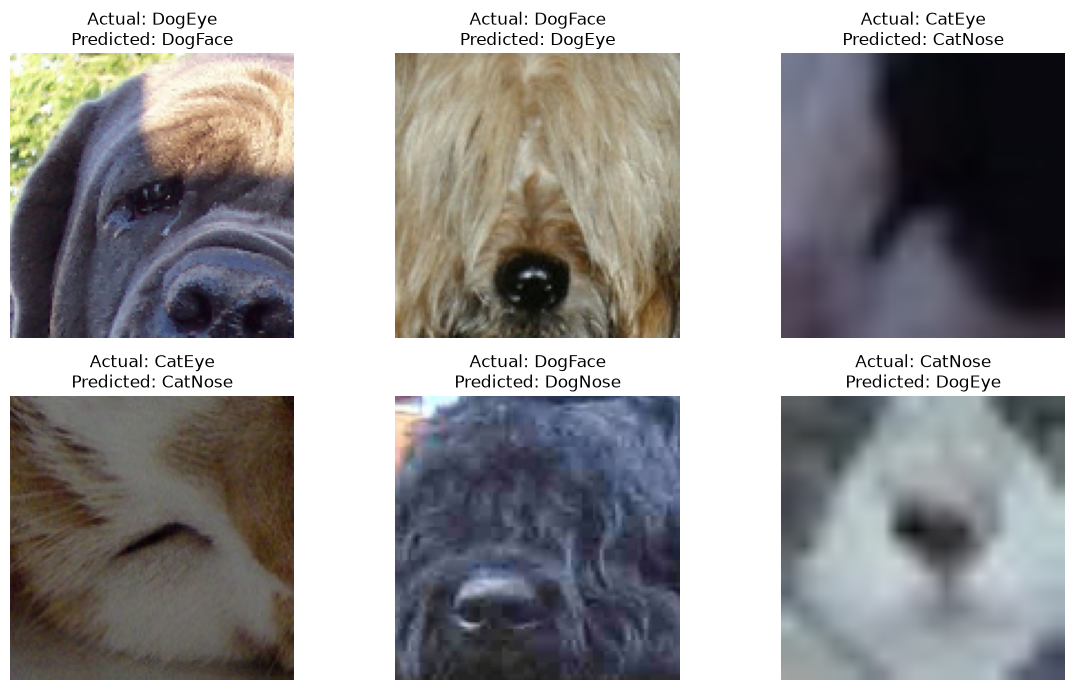

In [33]:
plt.figure(figsize=(12, 7))

for i, index in enumerate(wrong_indices[:6]):
    image, _ = load_image(
        tf.constant(val_paths[index]),
        tf.constant(val_labels[index])
    )

    plt.subplot(2, 3, i + 1)
    plt.imshow(image.numpy())

    actual = class_names[val_labels[index]]
    predicted = class_names[predictions[index]]

    plt.title(f"Actual: {actual}\nPredicted: {predicted}")
    plt.axis("off")

plt.tight_layout()
plt.show()